# Market Overview

## Research question
How do German price levels and tails differ from average-price budgeting?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
Hourly price = sum(price x minutes)/60, only with complete coverage. Retain zero/negative prices and native market intervals.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.validation.quality import hourly_prices
native = pd.read_parquet('data/processed/prices.parquet')
hourly = hourly_prices(native)
display(hourly.price_eur_mwh.describe())
display(json.loads(Path('reports/market_summary.json').read_text()))

count    34032.000000
mean        95.239742
std         59.580814
min       -500.000000
25%         67.847500
50%         94.920000
75%        122.286250
max        936.280000
Name: price_eur_mwh, dtype: float64

{'native_intervals': 63843,
 'valid_hourly_observations': 34032,
 'mean_hourly_price_eur_mwh': 95.23974171368123,
 'native_min_price': -500.0,
 'native_max_price': 936.28,
 'negative_price_hours': 1797.75,
 'negative_time_share': 0.052825282087447106,
 'negative_episodes': 376,
 'mean_daily_spread': 121.67815761636108,
 'absolute_change_lag1_correlation': 0.5237253204128182}

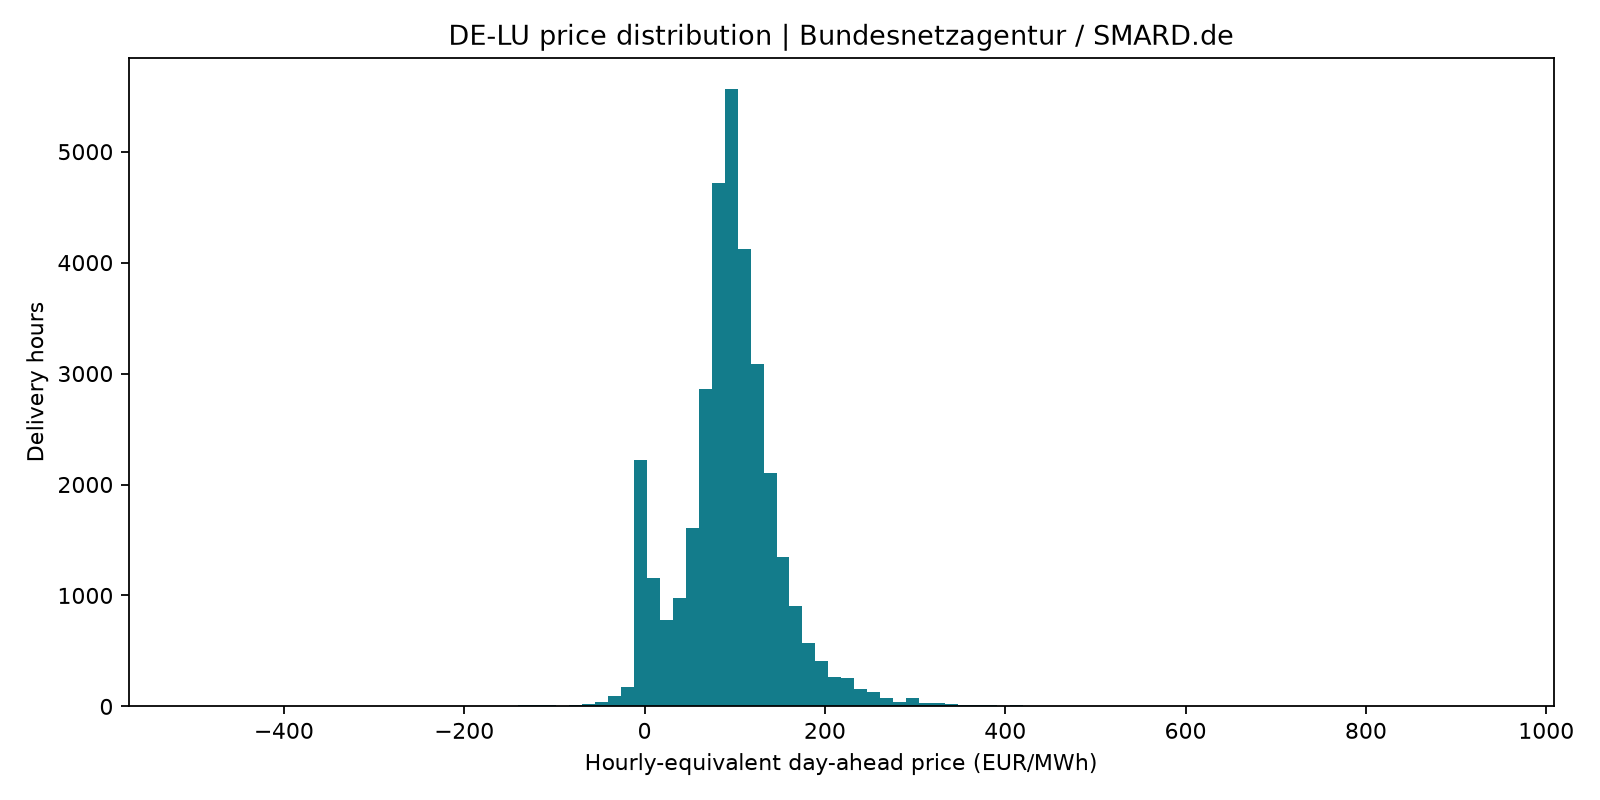

In [3]:
display(Image(filename='reports/price_distribution.png'))

## Quantitative findings and commercial interpretation
The EUR 95.24/MWh average coexists with native prices from -500 to 936.28 EUR/MWh and 5.28% negative delivery time. Purchasers and generators face opposing price-tail exposures; merit-order reasoning alone does not identify causality.

## Limitations
Post-transition hourly averaging hides quarter-hour extremes. Historical price levels are not forward expectations or traded returns.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.